<a href="https://colab.research.google.com/github/ssegovia99/diplomado-m6-santiago-segovia/blob/main/talleres/clase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- m6:clase=1;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 1 — Encuadre, app simulada, KNN, métodos kernel y árboles
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · miércoles 11-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas 🔵 de demostración ya están completas: ejecútelas y observe.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas.
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** (no la plantilla) → ruta `talleres/clase1.ipynb`. **Plazo: hoy hasta las 22:30.**

> Todos los datos provienen de **PagoYa**, una app de pagos móviles **ficticia**: los eventos son simulados con fines didácticos.

## 0. Preparación

In [1]:
import os, urllib.request                                   # utilidades para descargar archivos
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):                          # descarga las funciones del curso una sola vez
    urllib.request.urlretrieve(URL, 'curso.py')
import curso                                                # API simulada, EDA y checkpoints
import json, time, warnings                                 # JSON, medición de tiempos y avisos
warnings.filterwarnings('ignore')
import numpy as np                                          # cálculo numérico
import pandas as pd                                         # tablas
import matplotlib.pyplot as plt                             # gráficos
from sklearn.model_selection import train_test_split, cross_val_score   # partición y validación cruzada
from sklearn.preprocessing import StandardScaler            # escalado (media 0, desviación 1)
from sklearn.pipeline import make_pipeline                  # encadena escalado + modelo
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC                                 # máquina de soporte vectorial
from sklearn.kernel_ridge import KernelRidge                # regresión ridge con kernel
from sklearn.linear_model import Ridge                      # ridge lineal (comparación)
from sklearn.tree import DecisionTreeClassifier             # árbol de decisión
from sklearn.metrics import balanced_accuracy_score, recall_score   # métricas de clasificación
plt.rcParams['figure.figsize'] = (10, 3.6)
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


---
## 1.1 Encuadre: ciclo PDCA y CRISP-DM
Cada clase sigue el ciclo **Planificar → Hacer → Verificar → Actuar** (Deming) aplicado a un proyecto de datos (CRISP-DM):
**entender el negocio → entender los datos → preparar → modelar → evaluar → desplegar**. Hoy recorremos las cinco primeras fases con la app PagoYa.

---
## 1.2 Repositorio en GitHub y registro (Checkpoint 0)
Su repositorio `diplomado-m6-apellido` se creó desde la plantilla del curso. Este cuaderno se guarda en él al final de la clase.

### ✏️ Checkpoint 0 · ⏱ 3 min
Escriba su nombre como **'Apellido Nombre'** y ejecute. Debe aparecer ✅ con su código.

In [2]:
curso.registrar('Segovia Santiago')          # ✏️ su apellido y nombre, ej. 'Pérez Juan'

Estudiante registrado: Segovia Santiago
✅ Checkpoint 0 correcto · código K0-1211


---
## 1.3 App simulada PagoYa: eventos JSON desde una API REST
Una app envía cada transacción como un **evento JSON** a un servidor. Nosotros los pedimos a la API por **páginas**, igual que con una API real.

In [3]:
api = curso.APIPagoYa()                                     # 'conecta' con la API simulada
resp = api.get('/v1/transacciones', pagina=1, por_pagina=500)  # GET de la primera página
print('status:', resp['status'], '· total de eventos:', resp['total'], '· páginas:', resp['paginas'])
print(json.dumps(resp['datos'][0], indent=2, ensure_ascii=False))   # un evento tal como llega

status: 200 · total de eventos: 3006 · páginas: 7
{
  "evento_id": "TX-000000",
  "timestamp": "2026-09-19T17:57:21-05:00",
  "usuario": {
    "id": "U0756",
    "edad": 60,
    "provincia": "Pichincha",
    "antiguedad_meses": 27,
    "ingreso_mensual": 841.44
  },
  "transaccion": {
    "tipo": "transferencia",
    "canal": "app",
    "categoria": "persona",
    "monto": 62.36
  },
  "contexto": {
    "dispositivo_nuevo": false,
    "distancia_km": 4.5,
    "intentos_pin": 1
  },
  "etiqueta": {
    "fraude": 0
  }
}


In [4]:
eventos = curso.descargar_todo(api)                         # recorre las 7 páginas
df = pd.json_normalize(eventos)                             # JSON anidado → tabla plana
df.columns = [c.split('.')[-1] for c in df.columns]         # 'usuario.edad' → 'edad'
df['timestamp'] = pd.to_datetime(df['timestamp'])           # texto → fecha y hora
df['hora'] = df['timestamp'].dt.hour                        # variable derivada: hora del día
df['dispositivo_nuevo'] = df['dispositivo_nuevo'].astype(int)
df.head(3)

Descargados 3006 eventos en 7 páginas de /v1/transacciones


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora
0,TX-000000,2026-09-19 17:57:21-05:00,U0756,60.0,Pichincha,27,841.44,transferencia,app,persona,62.36,0,4.5,1,0,17
1,TX-000001,2026-10-19 21:50:18-05:00,U0540,22.0,Azuay,47,1050.30,recarga,app,telefonia,16.93,1,1.5,2,0,21
2,TX-000002,2026-09-09 11:51:27-05:00,U0203,25.0,Guayas,57,675.65,recarga,web,telefonia,8.19,0,4.3,1,0,11


In [5]:
curso.eda_rapido(df, objetivo='fraude', id_col='evento_id')   # EDA automático de calidad

Filas: 3,006 · Columnas: 16
IDs duplicados (evento_id): 6
Tasa de 'fraude': 8.42%


,tipo,nulos,% nulos,valores_unicos,negativos,minimo,mediana,maximo
antiguedad_meses,int64,0,0.0,60,0.0,1.0,29.0,60.0
canal,object,0,0.0,2,,,,
categoria,object,0,0.0,8,,,,
dispositivo_nuevo,int64,0,0.0,2,0.0,0.0,0.0,1.0
distancia_km,float64,0,0.0,260,0.0,0.0,4.1,63.6
edad,float64,30,1.0,53,0.0,18.0,44.0,70.0
evento_id,object,0,0.0,3000,,,,
fraude,int64,0,0.0,2,0.0,0.0,0.0,1.0
hora,int32,0,0.0,24,0.0,0.0,14.0,23.0
id,object,0,0.0,773,,,,


In [6]:
df_limpio = (df.drop_duplicates('evento_id')               # 1) quita eventos reenviados
               .query('monto > 0')                          # 2) quita montos negativos
               .copy())
df_limpio['edad'] = df_limpio['edad'].fillna(df_limpio['edad'].median())   # 3) imputa edad con la mediana
print('Filas antes:', len(df), '· después:', len(df_limpio))

Filas antes: 3006 · después: 2996


### ✏️ Checkpoint 1 · ⏱ 4 min
Calcule la **tasa de fraude** (proporción de 1 en la columna `fraude`) del DataFrame **limpio**.

In [7]:
tasa = df_limpio['fraude'].mean()          # ✏️ promedio de una variable 0/1 = proporción
print(f'Tasa de fraude: {tasa:.2%}')
curso.checkpoint(1, tasa)

Tasa de fraude: 8.44%
✅ Checkpoint 1 correcto · código K1-60A6


### 💬 Pregunta 1
El EDA encontró duplicados, nulos y montos negativos. Para cada problema, ¿qué decisión tomó el código y qué riesgo habría si se modelara sin corregirlo?

**Respuesta:** Los duplicados se eliminaron (con drop_duplicates) porque inflaban la frecuencia de los eventos. El modelo le daba  demasiada importancia a transacciones repetidas.

Montos negativos: Se filtraron (monto > 0) porque un pago no puede ser negativo. El modelo podría equivocarse al calcular distancias o promedios.

Nulos en edad: Se imputaron con la mediana porque la predicción falla si tienen valores nulos.

---
## 1.4 KNN: k vecinos más cercanos
Para clasificar una transacción, KNN busca las **k más parecidas** del entrenamiento y vota. "Parecidas" = **distancia**: por eso la **escala** de las variables importa.

In [8]:
X_cols = ['edad', 'antiguedad_meses', 'ingreso_mensual', 'monto', 'hora',
          'distancia_km', 'intentos_pin', 'dispositivo_nuevo']   # variables numéricas
X = df_limpio[X_cols]                                       # matriz de variables
y = df_limpio['fraude']                                     # objetivo: 1 = fraude
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)       # 70/30 manteniendo la tasa de fraude
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape)

Entrenamiento: (2097, 8) · Prueba: (899, 8)


In [9]:
knn_sin = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)   # KNN SIN escalar
print('Exactitud balanceada sin escalar:', round(balanced_accuracy_score(y_test, knn_sin.predict(X_test)), 4))
print('Desviaciones:', X_train.std().round(1).to_dict())   # ingreso y monto dominan la distancia

Exactitud balanceada sin escalar: 0.5424
Desviaciones: {'edad': 14.8, 'antiguedad_meses': 17.7, 'ingreso_mensual': 449.5, 'monto': 92.4, 'hora': 5.8, 'distancia_km': 5.9, 'intentos_pin': 0.6, 'dispositivo_nuevo': 0.4}


### ✏️ Checkpoint 2 · ⏱ 5 min
Construya un **Pipeline** que **escale** y luego aplique KNN con **k = 5**. Calcule la **exactitud balanceada** en prueba.

In [10]:
knn_esc = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))   # ✏️
knn_esc.fit(X_train, y_train)
acc = balanced_accuracy_score(y_test, knn_esc.predict(X_test))
print('Exactitud balanceada escalado:', round(acc, 4))
curso.checkpoint(2, acc)

Exactitud balanceada escalado: 0.6745
✅ Checkpoint 2 correcto · código K2-549C


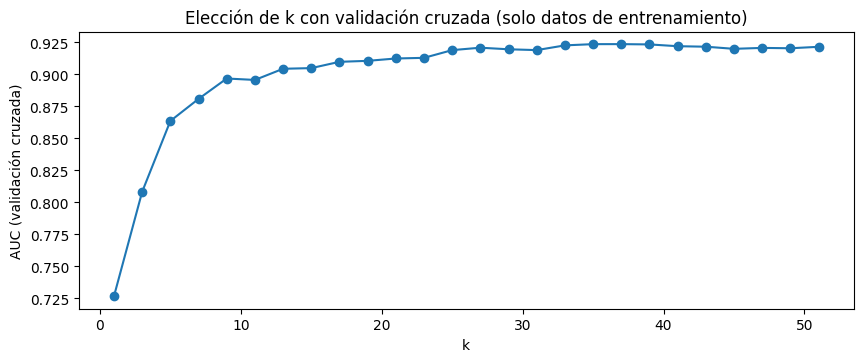

In [11]:
ks = list(range(1, 52, 2))                                  # k impares de 1 a 51
puntajes = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                            X_train, y_train, cv=5, scoring='roc_auc').mean() for k in ks]
plt.plot(ks, puntajes, marker='o'); plt.xlabel('k'); plt.ylabel('AUC (validación cruzada)')
plt.title('Elección de k con validación cruzada (solo datos de entrenamiento)'); plt.show()

### ✏️ Checkpoint 3 · ⏱ 4 min
Obtenga el **k con mayor puntaje** de la lista `ks`.

In [12]:
k_mejor = ks[np.argmax(puntajes)]          # ✏️ posición del máximo
print('k óptimo:', k_mejor)
curso.checkpoint(3, k_mejor)

k óptimo: 37
✅ Checkpoint 3 correcto · código K3-2E88


In [16]:
#Para medir los errores
Xr = pd.get_dummies(df_limpio[['ingreso_mensual', 'edad', 'hora', 'tipo']], columns=['tipo'], dtype=int)
yr = df_limpio['monto']                                     # KNN también sirve para REGRESIÓN: predecir el monto
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=42)
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)).fit(Xr_tr, yr_tr)
print('RMSE KNN:', round(rmse(yr_te, knn_reg.predict(Xr_te)), 2),
      '· RMSE ingenuo (promedio):', round(rmse(yr_te, np.full(len(yr_te), yr_tr.mean())), 2))

RMSE KNN: 64.12 · RMSE ingenuo (promedio): 85.27


In [17]:
#Para medir la complejidad
KNeighborsClassifier(5, algorithm='brute').fit(np.random.rand(50, 8), np.arange(50) % 2).predict(np.random.rand(5, 8))  # calentamiento
for n in [2_000, 20_000, 200_000]:                          # costo O(n·d): cada consulta mide distancia a TODOS
    Xg = np.random.rand(n, 8); m = KNeighborsClassifier(5, algorithm='brute').fit(Xg, np.random.randint(0, 2, n))
    t = time.perf_counter(); m.predict(np.random.rand(500, 8))
    print(f'n = {n:>7,} → {time.perf_counter() - t:.3f} s para 500 consultas')

n =   2,000 → 0.022 s para 500 consultas
n =  20,000 → 0.240 s para 500 consultas
n = 200,000 → 1.410 s para 500 consultas


### 💬 Pregunta 2
¿Por qué la exactitud de KNN cambia al escalar las variables? Explique con el ejemplo del ingreso y de `dispositivo_nuevo`.

**Respuesta:** La exactitud cambia porque KNN se basa en distancias euclidianas. El ingreso_mensual está en miles de dólares (con cifras de 1000, 2000), mientras que dispositivo_nuevo solo varía entre 0 y 1. Sin escalar, la diferencia de mil dólares domina la diferencia de 1 unidad, haciendo que el algoritmo ignore si el dispositivo es nuevo. Al escalar (con StandardScaler), ambas variables tienen la misma importancia o relevancia matemática (media 0, desviación 1).

---
## 1.5 Métodos kernel: SVM con kernel RBF y kernel ridge
El **truco del kernel** mide la similitud entre observaciones como si estuvieran en un espacio de muchas más dimensiones, **sin calcularlo**: así una frontera lineal allá es **curva** aquí.

In [23]:
#Modelo para obtener figuras curvas con matematica lineal (producto punto en mas dimensiones, kernell gaussiano)
for kernel in ['linear', 'rbf']:                             # misma SVM, distinto kernel
    m = make_pipeline(StandardScaler(), SVC(kernel=kernel, class_weight='balanced')).fit(X_train, y_train)
    p = m.predict(X_test)
    print(f'{kernel:>6}: exactitud balanceada {balanced_accuracy_score(y_test, p):.3f} · recall de fraude {recall_score(y_test, p):.3f}')
m = SVC(kernel='rbf', class_weight='balanced').fit(X_train, y_train)   # RBF SIN escalar
print('rbf sin escalar: exactitud balanceada', round(balanced_accuracy_score(y_test, m.predict(X_test)), 3))

linear: exactitud balanceada 0.868 · recall de fraude 0.908
   rbf: exactitud balanceada 0.885 · recall de fraude 0.829
rbf sin escalar: exactitud balanceada 0.691


### ✏️ Checkpoint 4 · ⏱ 5 min
Entrene una SVM con kernel **RBF**, `class_weight='balanced'` y **datos escalados**. Calcule el **recall** de fraude.

In [19]:
svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced'))   # ✏️
svm_rbf.fit(X_train, y_train)
rec = recall_score(y_test, svm_rbf.predict(X_test))
print('Recall RBF:', round(rec, 4))
curso.checkpoint(4, rec)

Recall RBF: 0.8289
✅ Checkpoint 4 correcto · código K4-2DD2


In [20]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xr_tr, yr_tr)   # ridge LINEAL para el monto
print('RMSE ridge lineal:', round(rmse(yr_te, ridge.predict(Xr_te)), 2))
for n in [2_000, 20_000, 200_000]:                          # costo O(n²) en memoria de la matriz kernel
    print(f'n = {n:>7,} → matriz kernel de {n*n*8/1e9:,.2f} GB')

RMSE ridge lineal: 64.56
n =   2,000 → matriz kernel de 0.03 GB
n =  20,000 → matriz kernel de 3.20 GB
n = 200,000 → matriz kernel de 320.00 GB


### ✏️ Checkpoint 5 · ⏱ 5 min
Entrene **KernelRidge** con kernel **RBF**, `alpha=1.0` y `gamma=0.1` sobre `Xr` escalado. Calcule el **RMSE**.

In [21]:
kr = make_pipeline(StandardScaler(), KernelRidge(kernel='rbf', alpha=1.0, gamma=0.1))   # ✏️
kr.fit(Xr_tr, yr_tr)
error = rmse(yr_te, kr.predict(Xr_te))
print('RMSE kernel ridge:', round(error, 2))
curso.checkpoint(5, error)

RMSE kernel ridge: 62.11
✅ Checkpoint 5 correcto · código K5-3521


---
## 1.6 Árboles de decisión avanzados: poda, importancia y límites
Un árbol sin límites **memoriza** el entrenamiento. La **poda por complejidad** (`ccp_alpha`) recorta ramas que aportan poco.

In [24]:
arbol = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_train, y_train)   # árbol sin límites
ba = lambda m, X_, y_: balanced_accuracy_score(y_, m.predict(X_))   # exactitud balanceada abreviada
print('Hojas:', arbol.get_n_leaves(), '· entrenamiento:', round(ba(arbol, X_train, y_train), 3),
      '· prueba:', round(ba(arbol, X_test, y_test), 3))

Hojas: 123 · entrenamiento: 1.0 · prueba: 0.786


In [25]:
ruta = arbol.cost_complexity_pruning_path(X_train, y_train)  # valores candidatos de ccp_alpha
alphas = ruta.ccp_alphas[:-1][::max(1, len(ruta.ccp_alphas) // 30)]   # ~30 candidatos
cv = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, class_weight='balanced', random_state=42),
                      X_train, y_train, cv=5, scoring='balanced_accuracy').mean() for a in alphas]
alpha_mejor = float(alphas[int(np.argmax(cv))])               # el mejor por validación cruzada
print('ccp_alpha elegido:', round(alpha_mejor, 5))

ccp_alpha elegido: 0.00964


### ✏️ Checkpoint 6 · ⏱ 5 min
Entrene el **árbol podado** con `ccp_alpha=alpha_mejor`, `class_weight='balanced'` y `random_state=42`. Calcule la **exactitud balanceada** en prueba.

In [29]:
podado = DecisionTreeClassifier(ccp_alpha=alpha_mejor, class_weight='balanced', random_state=42)   # ✏️
podado.fit(X_train, y_train)
acc_p = ba(podado, X_test, y_test)
print('Hojas:', podado.get_n_leaves(), '· exactitud balanceada prueba:', round(acc_p, 4))
curso.checkpoint(6, acc_p)

Hojas: 9 · exactitud balanceada prueba: 0.8656
✅ Checkpoint 6 correcto · código K6-81BB


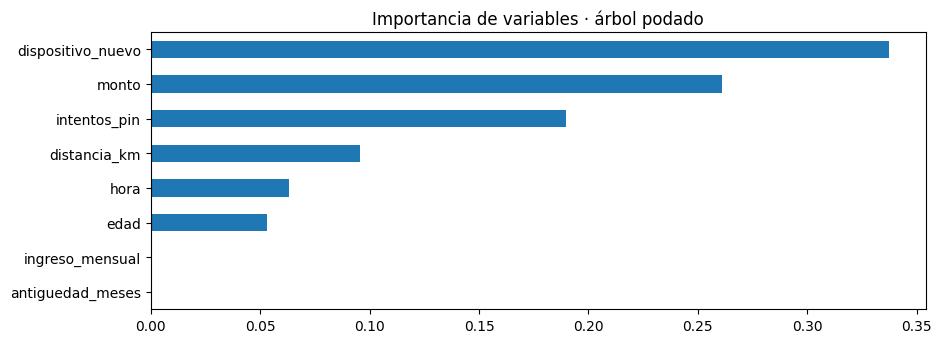

In [27]:
imp = pd.Series(podado.feature_importances_, index=X_cols).sort_values()   # importancia de cada variable
imp.plot.barh(title='Importancia de variables · árbol podado'); plt.show()

In [28]:
preds = []                                                  # límite: un árbol es INESTABLE
for semilla in [1, 2]:
    idx = X_train.sample(frac=1, replace=True, random_state=semilla).index   # otra muestra de los mismos datos
    a = DecisionTreeClassifier(class_weight='balanced', random_state=0).fit(X_train.loc[idx], y_train.loc[idx])
    preds.append(a.predict(X_test))                         # predicciones de cada árbol
print(f'Los dos árboles discrepan en {np.mean(preds[0] != preds[1]):.1%} de las transacciones de prueba')

Los dos árboles discrepan en 7.3% de las transacciones de prueba


### 💬 Pregunta 3
Según la importancia de variables, ¿qué patrón de fraude aprendió el árbol? ¿Por qué no basta un solo árbol para tomar decisiones en producción?

**Respuesta:** El árbol aprende que el patrón de fraude está asociado a dispositivos nuevos, montos altos, intentos de PIN fallidos, distancia y horas de la madrugada, en ese orden.
¿Por qué no basta un solo árbol? Porque es inestable. Como se ve en la última celda, si cambiamos ligeramente la muestra de entrenamiento (o sea, usando otra semilla), el árbol cambia su estructura y predice cosas distintas. En producción, un modelo debe ser robusto; para solucionar esto se usan ensambles como Random Forest o Gradient Boosting.

---
## Cierre de la clase

In [30]:
curso.resumen(total=7)                                      # avance de checkpoints

Estudiante: Segovia Santiago · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) (hasta las 22:30).


**Para terminar (hasta las 22:30):**
1. Revise que todos los checkpoints tengan ✅ y que las 3 preguntas 💬 tengan respuesta.
2. **Archivo → Guardar (Ctrl+S)** → en *Repositorio* cambie a **el suyo**: `su-usuario/diplomado-m6-apellido` → ruta `talleres/clase1.ipynb` → mensaje `Clase 1` → Aceptar.
3. En su repositorio, pestaña **Actions**: espere el círculo verde ✅ y abra el resumen del verificador.